# 第2回 adstock と saturation

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。
「🧪 実験」のセルだけは、数字を変えて何度か実行してみてください。

**この回のゴール**

広告には、ふつうの回帰分析では表せない性質が2つあります。それを表す2つの部品を、自分で関数を作って理解します。

1. **adstock（残存効果）**：今週の広告は、来週以降も効き続ける
2. **saturation（頭打ち）**：広告費を2倍にしても、効果は2倍にならない

**所要時間**：45〜60分。重い計算はありません。


> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/02-adstock-saturation>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


この回で使うライブラリを読み込みます。

In [2]:
import numpy as np
import pandas as pd

## 1. 全体像

MMMは、チャネルごとの広告費を次の順に変換して「売上への貢献」にします。

$$
\text{広告費 } x_t
\;\xrightarrow{\;\text{adstock}\;}\; A_t
\;\xrightarrow{\;\text{saturation}\;}\; S(A_t)
\;\xrightarrow{\;\times \beta\;}\; \text{売上への貢献}
$$

| 部品 | 表すこと | パラメータ |
|---|---|---|
| adstock | 効果が翌週以降にも残る | $\alpha$（翌週に残る割合） |
| saturation | 効果が頭打ちになる | $\lambda$（頭打ちの早さ） |
| 係数 | チャネルの効果の大きさ | $\beta$ |

この回では $\alpha$ と $\lambda$ を自分で決めて、変換の形を見ます。本番（第3〜4回）では、これらをデータから推定します。

## 2. adstock（残存効果）

### 2-1. 考え方と式

TVのCMを見た人は、その週だけでなく翌週も、その次の週も、少しずつ忘れながら覚えています。
そこで「今週の広告の効き目」を、今週の広告費だけでなく、過去の広告費の残りも足したものと考えます。

$$
A_t \;=\; x_t \;+\; \alpha\, x_{t-1} \;+\; \alpha^2 x_{t-2} \;+\; \cdots \;+\; \alpha^{L-1} x_{t-(L-1)}
\;=\; \sum_{l=0}^{L-1} \alpha^{\,l}\, x_{t-l}
$$

- $x_t$：$t$ 週の広告費
- $\alpha$：翌週に残る割合（0〜1）。0.5なら毎週半分になる
- $L$：何週前までさかのぼって足すか（コードでは `l_max`）

毎週同じ割合で減っていくので、**幾何減衰**（geometric adstock）と呼びます。

**手計算の例**（$\alpha = 0.5$）：1週目に100、2週目に50、3週目は0の広告を出したとき

- 1週目：$A_1 = 100$
- 2週目：$A_2 = 50 + 0.5 \times 100 = 100$
- 3週目：$A_3 = 0 + 0.5 \times 50 + 0.25 \times 100 = 50$

3週目は広告を出していないのに、50の効き目が残っています。

### 2-2. 関数にする

式をそのまま関数にします。`w` が重み（$1, \alpha, \alpha^2, \dots$）で、`np.convolve` が「過去の広告費に重みをかけて足す」計算をします。

In [3]:
def adstock(x, alpha, l_max=8):
    # 今週の広告効果が、毎週 alpha 倍ずつ減りながら残る
    w = alpha ** np.arange(l_max)          # 重み：1, alpha, alpha², ...
    return np.convolve(x, w)[:len(x)]

# 手計算の例と同じになるか確かめる
adstock(np.array([100, 50, 0]), alpha=0.5)

array([100., 100.,  50.])

手計算と同じ `[100, 100, 50]` になりました。

### 2-3. 1回だけ広告を出した場合

3週目に1回だけ100の広告を出して、その後どう残るかを見ます。

[  0.    0.  100.   50.   25.   12.5   6.2   3.1   1.6   0.8   0.    0. ]


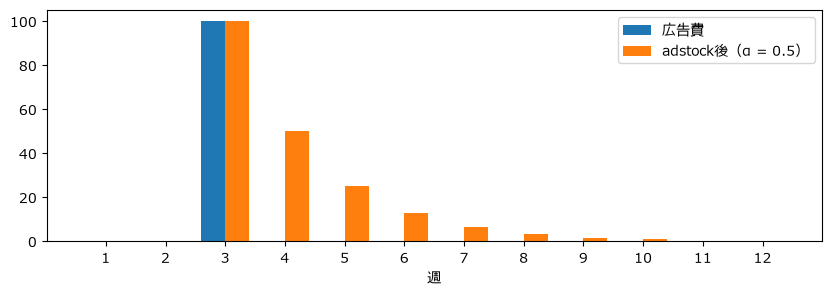

In [4]:
x = np.zeros(12)
x[2] = 100          # 3週目に1回だけ 100
weeks = np.arange(1, 13)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(weeks - 0.2, x, width=0.4, label="広告費")
ax.bar(weeks + 0.2, adstock(x, alpha=0.5), width=0.4, label="adstock後（α = 0.5）")
ax.set_xticks(weeks)
ax.set_xlabel("週")
ax.legend()

print(adstock(x, alpha=0.5).round(1))

**読み方**：広告を出した週は100、翌週50、その次25…と半分ずつ減っていきます。

### 2-4. α を変えるとどうなるか

$\alpha = 0.5$ と $\alpha = 0.9$ を比べます。

α = 0.5：5週間後の残り = 3.1、効き目の合計 = 199、半減期 = 1.0 週
α = 0.9：5週間後の残り = 59.0、効き目の合計 = 570、半減期 = 6.6 週


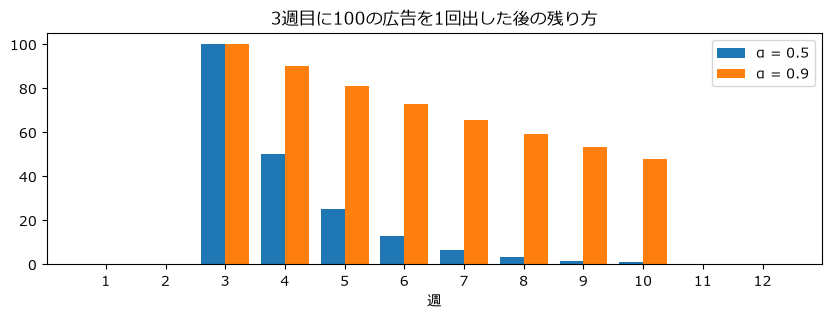

In [5]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(weeks - 0.2, adstock(x, alpha=0.5), width=0.4, label="α = 0.5")
ax.bar(weeks + 0.2, adstock(x, alpha=0.9), width=0.4, label="α = 0.9")
ax.set_xticks(weeks)
ax.set_xlabel("週")
ax.set_title("3週目に100の広告を1回出した後の残り方")
ax.legend()

for alpha in [0.5, 0.9]:
    a = adstock(x, alpha)
    half_life = np.log(0.5) / np.log(alpha)
    print(f"α = {alpha}：5週間後の残り = {a[7]:.1f}、効き目の合計 = {a.sum():.0f}、半減期 = {half_life:.1f} 週")

**読み方**

| | $\alpha = 0.5$ | $\alpha = 0.9$ |
|---|---|---|
| 5週間後の残り | 約3 | 約59 |
| 効き目の合計（8週分） | 199 | 570 |
| 半減期（半分になるまでの週数） | 1.0週 | 6.6週 |

同じ100の広告でも、$\alpha$ が大きいと効き目の合計は約3倍になります。**$\alpha$ はチャネルの評価を大きく左右します。**

- 半減期の式：$\alpha^{h} = 0.5$ を解いて $h = \dfrac{\ln 0.5}{\ln \alpha}$
- $\alpha = 0.9$ のグラフが8週で急に0になるのは、`l_max=8`（8週前までしか足さない）ためです。$\alpha$ が大きいときは `l_max` も大きくしないと、効果を切り捨ててしまいます

**チャネルによる違い**：TVのように「覚えてもらう」広告は $\alpha$ が大きめ、検索広告のように「いま欲しい人に出す」広告は小さめになりやすいと言われます。
広告の「インパクトの大きさ」ではなく、「役割の違い」で決まります。

## 3. saturation（頭打ち）

### 3-1. 考え方と式

同じ人に同じ広告を10回見せても、効果は1回目の10倍にはなりません。届く相手にも限りがあります。
広告費を増やすほど、追加の効果は小さくなっていきます。これを表すのが saturation です。

ケーススタディ1は、次のロジスティック型の式を使います。

$$
S(x) \;=\; \frac{1 - e^{-\lambda x}}{1 + e^{-\lambda x}}
$$

- $x$：adstock後の広告の量（0以上）
- $\lambda$：頭打ちの早さ。大きいほど早く頭打ちになる
- 出力は 0〜1。$x = 0$ のとき0で、$x$ が大きくなると1に近づく

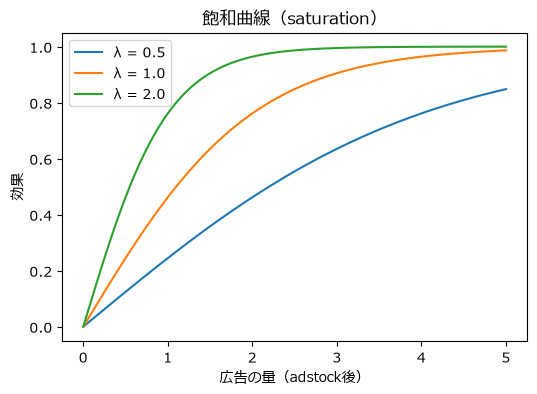

In [6]:
def saturation(x, lam):
    # 広告費が増えるほど、効果の伸びが鈍る
    return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))

x_grid = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(6, 4))
for lam in [0.5, 1.0, 2.0]:
    ax.plot(x_grid, saturation(x_grid, lam), label=f"λ = {lam}")
ax.set_xlabel("広告の量（adstock後）")
ax.set_ylabel("効果")
ax.set_title("飽和曲線（saturation）")
ax.legend();

**読み方**：どの曲線も、はじめは急に伸び、だんだん平らになります。$\lambda$ が大きいほど、早く平らになります。

### 3-2. 2倍にしても2倍にならない

$\lambda = 1$ のとき、広告の量を 1 → 2 → 4 と倍にしていきます。

In [7]:
values = saturation(np.array([1.0, 2.0, 4.0]), lam=1.0)
print("x = 1, 2, 4 のときの効果:", values.round(3))
print("1 → 2 にしたときの倍率:", round(values[1] / values[0], 2))
print("2 → 4 にしたときの倍率:", round(values[2] / values[1], 2))

x = 1, 2, 4 のときの効果: [0.462 0.762 0.964]
1 → 2 にしたときの倍率: 1.65
2 → 4 にしたときの倍率: 1.27


**読み方**：同じ「2倍」でも、1 → 2 では効果が1.65倍、2 → 4 では1.27倍にしかなりません。すでに多く出しているほど、増やしたときの伸びは小さくなります。

### 3-3. 限界効果 ― 予算配分の土台

「あと少しだけ広告を増やしたら、効果はどれだけ増えるか」を**限界効果**といいます。曲線の傾きのことです。式で書くと次のようになります。

$$
S'(x) \;=\; \frac{2\lambda\, e^{-\lambda x}}{\left(1 + e^{-\lambda x}\right)^2}
$$

x = 1, 2, 4 での限界効果: [0.39 0.21 0.04]


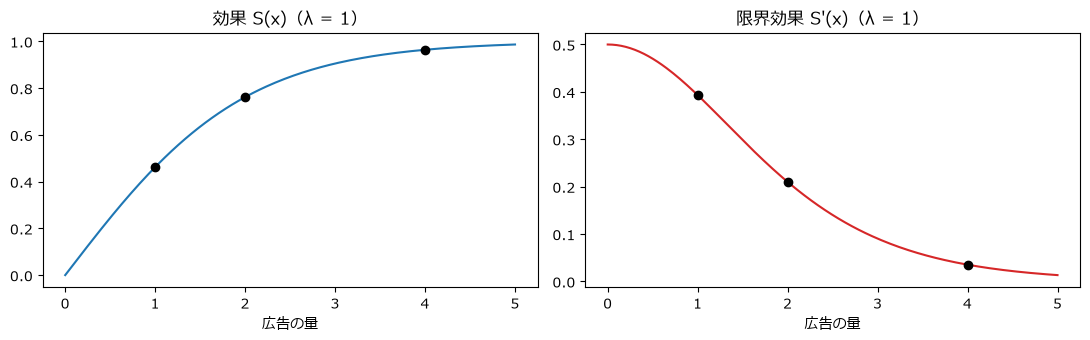

In [8]:
def marginal_effect(x, lam):
    # saturation の傾き（あと少し増やしたときの伸び）
    e = np.exp(-lam * x)
    return 2 * lam * e / (1 + e) ** 2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(x_grid, saturation(x_grid, 1.0))
axes[0].set_title("効果 S(x)（λ = 1）")
axes[0].set_xlabel("広告の量")
axes[1].plot(x_grid, marginal_effect(x_grid, 1.0), color="C3")
axes[1].set_title("限界効果 S′(x)（λ = 1）")
axes[1].set_xlabel("広告の量")
for xv in [1, 2, 4]:
    axes[0].scatter(xv, saturation(xv, 1.0), color="black", zorder=3)
    axes[1].scatter(xv, marginal_effect(xv, 1.0), color="black", zorder=3)
plt.tight_layout()

print("x = 1, 2, 4 での限界効果:", marginal_effect(np.array([1.0, 2.0, 4.0]), 1.0).round(2))

**読み方**：限界効果は $x = 1$ で0.39、$x = 2$ で0.21、$x = 4$ で0.04。すでに4まで出しているチャネルに追加しても、ほとんど効果は増えません。

**予算配分で比べるのは「平均の費用対効果」ではなく「限界効果」です。**

- 曲線の平らな部分にいるチャネル → これ以上増やしても伸びない。減らしても効果はあまり落ちない
- まだ急な部分にいるチャネル → 増やす価値がある

平らなチャネルから急なチャネルへ予算を移すと、同じ総額で効果が増えます。これが第7回（予算最適化）の考え方です。

## 4. データに当てはめる（TV費用）

第1回のデータのTV費用に、adstock → saturation を順にかけます。$\alpha = 0.6$、$\lambda = 2.0$ は仮に決めた値です。

### 4-1. 落とし穴：そのまま入れるとどうなるか

まず、費用をそのまま saturation に入れてみます。

In [9]:
df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])
tv = df["mdsp_vidtr"].to_numpy()

print("TV費用の最初の5週:", tv[:5].round(0))
print("そのまま saturation に入れた結果:", saturation(tv[:5], lam=2.0))

TV費用の最初の5週: [216726. 108919.  74032. 110996. 225141.]
そのまま saturation に入れた結果: [1. 1. 1. 1. 1.]


**全部 1.0 になりました。** 費用は数万〜100万という大きな数字なので、$e^{-\lambda x}$ がほぼ0になり、式が $\frac{1-0}{1+0} = 1$ になるためです。
「どの週も完全に頭打ち」という意味のない結果です。

**対策：スケーリング**。費用を最大値で割って、0〜1の大きさにそろえてから変換します。

### 4-2. スケーリングしてから変換する

最大値：① 1.0  ② 1.55  ③ 0.91


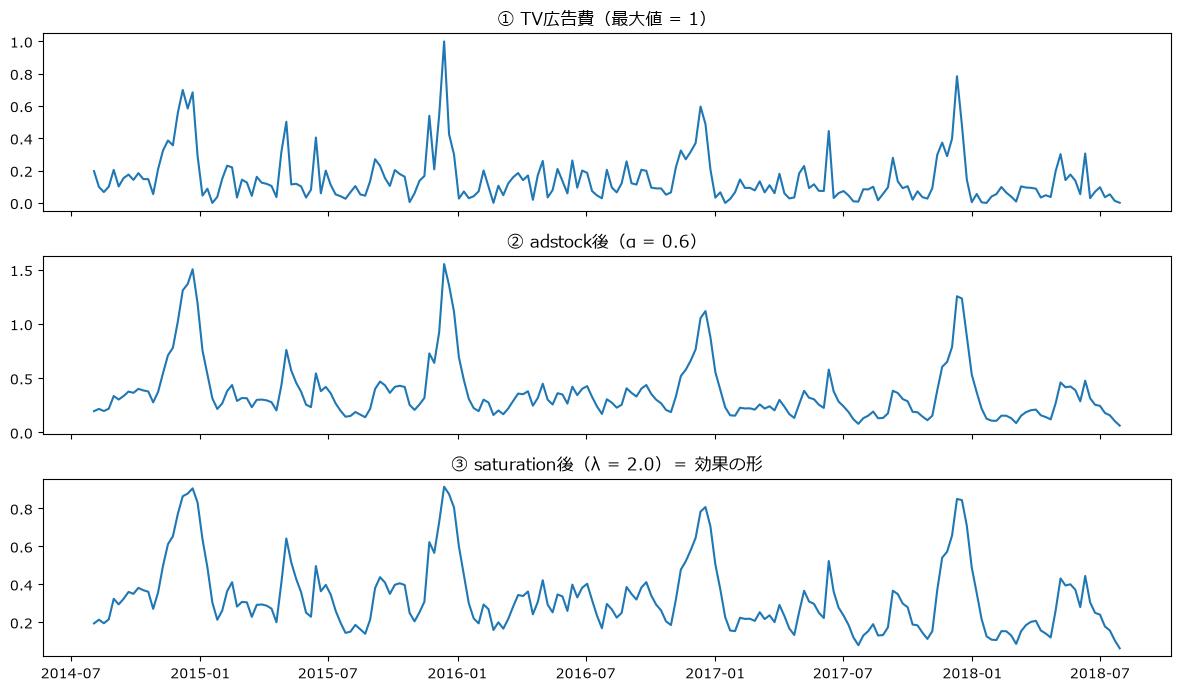

In [10]:
tv_scaled = tv / tv.max()                       # 最大値を1にそろえる
tv_adstock = adstock(tv_scaled, alpha=0.6)
tv_effect = saturation(tv_adstock, lam=2.0)

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(df["wk_strt_dt"], tv_scaled)
axes[0].set_title("① TV広告費（最大値 = 1）")
axes[1].plot(df["wk_strt_dt"], tv_adstock)
axes[1].set_title("② adstock後（α = 0.6）")
axes[2].plot(df["wk_strt_dt"], tv_effect)
axes[2].set_title("③ saturation後（λ = 2.0）＝ 効果の形")
plt.tight_layout()

print("最大値：①", tv_scaled.max().round(2), " ②", tv_adstock.max().round(2), " ③", tv_effect.max().round(2))

**読み方**

- **① → ②（adstock）**：ギザギザがなめらかになり、山が後ろに尾を引きます。過去の広告が積み重なるので、最大値は 1.0 → 約1.55 に増えます
- **② → ③（saturation）**：年末の大きな山が約0.91に押しつぶされます。小さい山はあまり縮みません。大きく出した週ほど、頭打ちの影響を強く受けるためです

③に係数 $\beta$ をかけたものが「TVによる売上」になります。本番では $\alpha$・$\lambda$・$\beta$ をデータから推定します。

> PyMC-Marketing の `MMM` は、このスケーリング（最大値で割る）を自動で行います。第3回で確かめます。

## 5. 🧪 実験：α と λ を変えてみる

下のセルの `ALPHA` と `LAM` を変えて、形がどう変わるか確かめてください。

- `ALPHA`：0.1、0.6、0.9 など
- `LAM`：0.5、2.0、5.0 など

adstock後の最大値: 1.55 / saturation後の最大値: 0.91
saturation後が0.8を超える週の数: 10 / 209


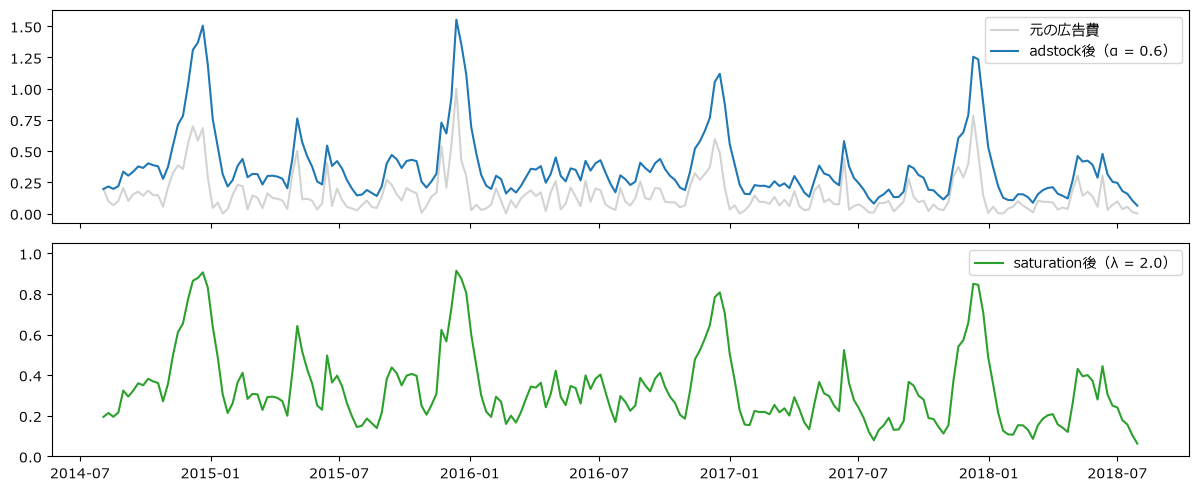

In [11]:
ALPHA = 0.6
LAM = 2.0

test_adstock = adstock(tv_scaled, alpha=ALPHA)
test_effect = saturation(test_adstock, lam=LAM)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(df["wk_strt_dt"], tv_scaled, color="lightgray", label="元の広告費")
axes[0].plot(df["wk_strt_dt"], test_adstock, label=f"adstock後（α = {ALPHA}）")
axes[0].legend(loc="upper right")
axes[1].plot(df["wk_strt_dt"], test_effect, color="C2", label=f"saturation後（λ = {LAM}）")
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc="upper right")
plt.tight_layout()

print("adstock後の最大値:", test_adstock.max().round(2), "/ saturation後の最大値:", test_effect.max().round(2))
print("saturation後が0.8を超える週の数:", int((test_effect > 0.8).sum()), "/", len(test_effect))

## 6. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　5章のセルで `ALPHA` を 0.6 から 0.9 に変えると、adstock後のグラフはどう変わりますか。saturation後はどうなりますか。

<details>
<summary>答えを見る</summary>

adstock後は、全体が上に持ち上がり、さらになめらかになって、山の尾が長くなります（最大値は約1.55 → 約2.92）。
効果が長く残るので、過去の広告がどんどん積み重なるためです。

saturation後は、0.8を超える週が10週 → 39週に増えます。年末以外の時期も高い水準になり、山と谷の差が小さくなります。
「効果が長く残るチャネルは、いつも頭打ちに近い状態になりやすい」ということです。

</details>

**課題2**　`ALPHA = 0.6` に戻し、`LAM` を 2.0 から 5.0 に変えると、saturation後のグラフはどう変わりますか。

<details>
<summary>答えを見る</summary>

最大値が約0.91 → 1.00になり、0.8を超える週が10週 → 42週に増えます。年末の山は上がつぶれて、平らな台のような形になります。
小さな広告費の週でも効果が大きく出て、少し多い週はすぐ上限に張りつきます。
λ が大きいチャネルは「少ない広告で頭打ちになる」チャネルで、多く出しても無駄になりやすいということです。

</details>

**課題3**　あるチャネルが、飽和曲線の平らな部分にいると分かりました。広告の担当者は「このチャネルは売上への貢献が一番大きいので、予算を増やしたい」と言っています。どう答えますか。

<details>
<summary>答えを見る</summary>

増やすことは勧めません。「貢献が大きい」ことと「増やせば伸びる」ことは別です。
平らな部分にいるチャネルは、追加で出しても効果がほとんど増えません（限界効果が小さい）。
むしろ少し減らしても効果はあまり落ちないので、その分を、まだ曲線の急な部分にいるチャネルへ回すほうが、同じ総額で売上が増えます。

</details>

**課題4**　TVと検索広告では、どちらの $\alpha$（翌週に残る割合）が大きくなりそうですか。理由も考えてください。

<details>
<summary>答えを見る</summary>

一般にはTVのほうが大きくなりやすいと言われます。
TVは「ブランドや商品を覚えてもらう」広告で、見た人が後日買うことが多いためです。
検索広告は「いま探している人」に出すので、効果の多くはその場（その週）で出ます。
ただしこれは一般論で、実際の値は商材やデータによって変わります。第4回で、このデータでの推定結果を確かめます。

</details>

## 7. まとめ

- MMMは広告費を「adstock → saturation → ×β」の順に変換して、売上への貢献にする
- **adstock**：$A_t = \sum \alpha^l x_{t-l}$。$\alpha$ は翌週に残る割合。$\alpha$ が 0.5 → 0.9 になると、効き目の合計は約3倍
- **saturation**：$S(x) = \dfrac{1 - e^{-\lambda x}}{1 + e^{-\lambda x}}$。$\lambda$ が大きいほど早く頭打ち
- 広告を2倍にしても効果は2倍にならない（1 → 2 で1.65倍、2 → 4 で1.27倍）
- 予算配分で比べるのは**限界効果**（あと少し増やしたときの伸び）
- 費用はそのまま入れず、**最大値で割ってから**変換する（そのままだと全部1.0になる）

**次回（第3回）**：ケーススタディ1の7チャネルでMMMを組み立てます。$\alpha$・$\lambda$・$\beta$ に「事前分布」を置き、学習前にモデルの様子を確かめます。